# 06_02 Confidence Intervals: How Sure Are We?

**Learning objectives**
- State exactly what "95 % confidence" means (a property of the *procedure*, checked by coverage simulation) and what it does **not** mean.
- Build intervals from a **pivotal quantity**: the $z$ and $t$ intervals for a mean, the chi-square interval for a variance, and the **Wald, Wilson and exact (Clopper-Pearson)** intervals for a proportion.
- Choose the **sample size** needed for a target margin of error.
- Compare interval methods by their **coverage** over a grid of true values, in 2D and in 3D.

**Prerequisites:** [05_03 Sampling distributions and the standard error](../../module_05_sampling/notebooks/05_03_sampling_distributions_standard_error.ipynb), [05_04 The bootstrap](../../module_05_sampling/notebooks/05_04_bootstrap_monte_carlo.ipynb), [06_01 Estimation](06_01_estimation_mle_mom.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math

## 2. Prerequisite recap

- The **standard error** of the sample mean is $\sigma/\sqrt n$, estimated by $s/\sqrt n$; for large $n$ the sample mean is approximately Normal (CLT, 05_02).
- For Normal data $\dfrac{\bar X-\mu}{s/\sqrt n}\sim t_{n-1}$ and $\dfrac{(n-1)s^2}{\sigma^2}\sim\chi^2_{n-1}$ (02_08, 05_03).
- A proportion $\hat p=k/n$ has $\mathrm{SE}=\sqrt{p(1-p)/n}$ (01_01).
- **Quantiles:** $z_{0.975}=1.96$; `stats.t.ppf`, `stats.chi2.ppf` give the others.

## 3. Intuition and story

A single number ("the mean delivery time is 31.2 minutes") hides how much a sample can fluctuate. A **confidence interval** adds the missing information: a range of plausible values for the unknown parameter, like "27.7 to 34.7 minutes".

The exact meaning is subtle and worth getting right. The parameter is a **fixed** number; the interval is **random** because it is computed from a random sample. A 95 % interval procedure is built so that, if you repeated the whole study many times, **95 % of the intervals would contain the true value**. It is a statement about the long-run behaviour of the *recipe*, not a 95 % probability about one finished interval.

The recipe always has the same shape: **estimate $\pm$ critical value $\times$ standard error**. What changes between cases is the estimate, the standard error and the distribution that supplies the critical value.

## 4. Formal definitions

A $(1-\alpha)$ **confidence interval** for $\theta$ is a pair of statistics $(L,U)$ computed from the data such that $P_\theta(L\le\theta\le U)\ge1-\alpha$ for every $\theta$ (the **coverage**).

| Situation | Interval | Distribution used |
|---|---|---|
| Mean, $\sigma$ known | $\bar x\pm z_{1-\alpha/2}\,\sigma/\sqrt n$ | Normal |
| Mean, $\sigma$ unknown | $\bar x\pm t_{n-1,1-\alpha/2}\,s/\sqrt n$ | Student $t_{n-1}$ |
| Variance (Normal data) | $\Big(\dfrac{(n-1)s^2}{\chi^2_{n-1,1-\alpha/2}},\ \dfrac{(n-1)s^2}{\chi^2_{n-1,\alpha/2}}\Big)$ | chi-square |
| Proportion, **Wald** | $\hat p\pm z\sqrt{\hat p(1-\hat p)/n}$ | Normal (approximate) |
| Proportion, **Wilson** | $\dfrac{\hat p+\frac{z^2}{2n}\pm z\sqrt{\frac{\hat p(1-\hat p)}n+\frac{z^2}{4n^2}}}{1+z^2/n}$ | Normal, test inverted |
| Proportion, **exact** (Clopper-Pearson) | Beta quantiles: $\big(B_{\alpha/2}(k,n-k+1),\,B_{1-\alpha/2}(k+1,n-k)\big)$ | Binomial / Beta |
| Any statistic | percentile interval of bootstrap resamples (05_04) | empirical |
| Likelihood | $\{\theta:\ell(\hat\theta)-\ell(\theta)\le\tfrac12\chi^2_{1,1-\alpha}\}$ (06_01) | chi-square |

**Margin of error** $m=z\,\sigma/\sqrt n$; to achieve a target $m$ one needs $n\ge(z\sigma/m)^2$.

## 5. Derivations

### 5.1 The $t$ interval from a pivot
A **pivot** is a function of the data and the parameter whose distribution does not depend on the parameter. For Normal data $T=\dfrac{\bar X-\mu}{s/\sqrt n}\sim t_{n-1}$. Hence $P(-t_c\le T\le t_c)=1-\alpha$, and solving the inequality for $\mu$ gives $\bar X-t_c\,s/\sqrt n\le\mu\le\bar X+t_c\,s/\sqrt n$. **In plain words.** The pivot measures "how many estimated standard errors the sample mean is from the truth", a quantity with a known distribution; flip the inequality to bracket the truth.

### 5.2 Why $t$ and not $z$
Replacing $\sigma$ by $s$ adds uncertainty (a small sample can have a small $s$ by chance), so the pivot has heavier tails than the Normal. The critical value is larger ($t_{24,0.975}=2.064$ against $1.96$), and it converges to $1.96$ as $n$ grows (Slutsky, 05_06). **In plain words.** The $t$ interval is wider when the sample is small because we are also unsure about the spread.

### 5.3 The variance interval
$(n-1)s^2/\sigma^2\sim\chi^2_{n-1}$ is a pivot; $P\big(\chi^2_{\alpha/2}\le(n-1)s^2/\sigma^2\le\chi^2_{1-\alpha/2}\big)=1-\alpha$ and inverting gives the interval. It is **not symmetric** around $s^2$ (the chi-square is skewed) and it is very sensitive to non-Normal tails. **In plain words.** Spreads are harder to pin down than means: with 25 observations the SD is only known to within about $\pm30\,\%$.

### 5.4 Wald, Wilson and exact intervals for a proportion
**Wald:** $\hat p\pm z\sqrt{\hat p(1-\hat p)/n}$ plugs the estimate into the standard error, which fails when $\hat p$ is near 0 or 1 (it can even leave $[0,1]$). **Wilson** solves $|\hat p-p|\le z\sqrt{p(1-p)/n}$ for $p$ (the *true* $p$ in the standard error), giving a quadratic whose roots are the interval: always inside $[0,1]$ and much better coverage. **Clopper-Pearson** inverts the exact Binomial tails and is guaranteed to cover at least $1-\alpha$ (it is conservative). **In plain words.** Wald asks "is the estimate within 1.96 SEs of the truth, computed *at the estimate*"; Wilson asks the same question *at the candidate truth*, which is the logically correct way round.

### 5.5 Sample size for a margin of error
$m=z\sigma/\sqrt n\Rightarrow n=(z\sigma/m)^2$. For a proportion the worst case is $p=\frac12$: $n=z^2/(4m^2)$, about 1,068 for $\pm3$ points at 95 %. Halving the margin needs **four times** the data. **In plain words.** Precision is expensive: it grows only like the square root of the sample size.

### 5.6 Intervals and tests are two views of one thing
The $(1-\alpha)$ interval is exactly the set of parameter values that a level-$\alpha$ test would **not** reject (06_03). **In plain words.** If 30 is outside your 95 % interval for the mean, the test of "mean = 30" would reject at the 5 % level.

## 6. Properties and relationships

- **Width:** the interval narrows like $1/\sqrt n$, widens with $\sigma$ and with the confidence level (99 % is about 30 % wider than 95 %).
- **Coverage is a property of the method,** not of one interval; it can be checked by simulation, and it may differ from the nominal level for small samples or skewed data (the $t$ interval is robust for means, not for variances).
- **Several methods for the same quantity:** Wald, Wilson and exact for proportions; bootstrap and likelihood intervals when no formula exists. Prefer methods with good coverage over the simplest formula.
- **Invariance:** an interval for $\theta$ transforms to an interval for $g(\theta)$ when $g$ is monotone (a log-scale interval for an odds ratio, 05_06).
- **Confidence versus credible:** a Bayesian *credible* interval (Module 07) does give a probability statement about the parameter, at the cost of a prior.

## 7. 2D visuals

### 7.1 The 100-intervals picture
Draw 100 independent samples of $n=25$ from a population with mean 30 and build a 95 % $t$-interval from each. About 5 of them miss the true mean (shown in orange): the confidence level describes the *procedure*.

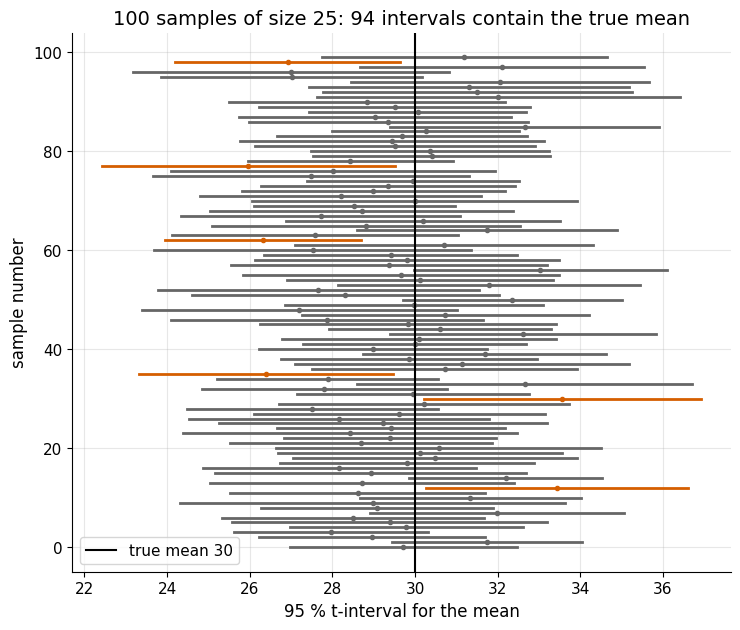

In [2]:
mu_true, sd_true, n_s = 30.0, 8.0, 25
fig, ax = plt.subplots(figsize=(8.5, 7))
t_c = stats.t(n_s - 1).ppf(0.975); miss = 0
for i in range(100):
    smp = rng.normal(mu_true, sd_true, n_s); m, se = smp.mean(), smp.std(ddof=1) / np.sqrt(n_s); lo, hi = m - t_c * se, m + t_c * se
    hit = lo <= mu_true <= hi; miss += not hit
    ax.plot([lo, hi], [i, i], color=NEUTRAL if hit else HIGHLIGHT, linewidth=2); ax.plot(m, i, "o", color=NEUTRAL if hit else HIGHLIGHT, markersize=3)
ax.axvline(mu_true, color="black", label="true mean 30"); ax.set_xlabel("95 % t-interval for the mean"); ax.set_ylabel("sample number"); ax.set_title(f"100 samples of size 25: {100 - miss} intervals contain the true mean"); ax.legend()
plt.show()
assert 85 <= 100 - miss <= 100

### 7.2 $t$ versus $z$ critical values
The critical value for a 95 % interval as a function of the sample size: $t_{n-1}$ is large for small $n$ and tends to 1.96.

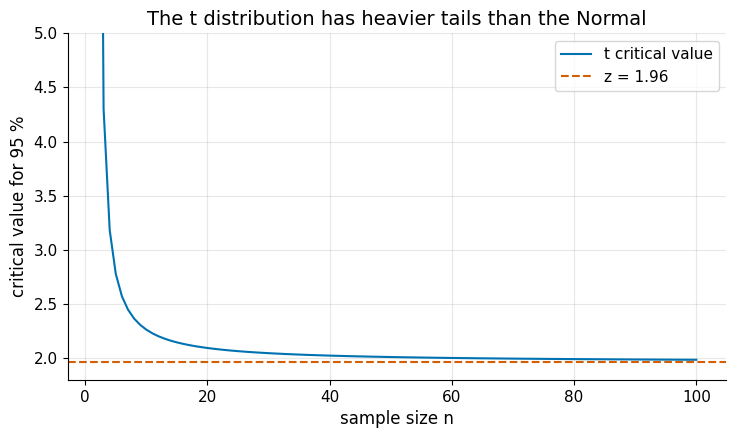

{3: np.float64(4.303), 5: np.float64(2.776), 10: np.float64(2.262), 25: np.float64(2.064), 100: np.float64(1.984)}


In [3]:
ns = np.arange(2, 101)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(ns, stats.t.ppf(0.975, ns - 1), color=MAIN, label="t critical value"); ax.axhline(1.96, color=HIGHLIGHT, linestyle="--", label="z = 1.96")
ax.set_ylim(1.8, 5); ax.set_xlabel("sample size n"); ax.set_ylabel("critical value for 95 %"); ax.set_title("The t distribution has heavier tails than the Normal"); ax.legend()
plt.show()
print({n_: round(stats.t.ppf(0.975, n_ - 1), 3) for n_ in (3, 5, 10, 25, 100)})
assert abs(stats.t.ppf(0.975, 24) - 2.0639) < 1e-3

### 7.3 Width against sample size and confidence level
The half-width of the interval for a mean ($\sigma=8$): it falls like $1/\sqrt n$ and rises with the confidence level.

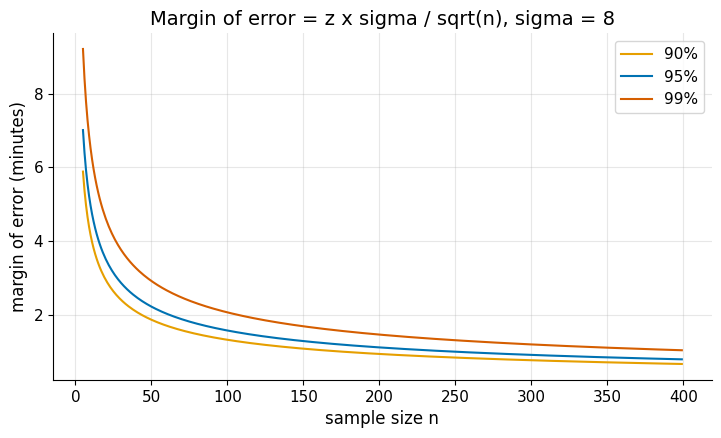

n for a margin of +/- 2 at 95 %: 62 | halving the margin needs 246 observations (4 times as many)


In [4]:
nn = np.arange(5, 400)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for conf, c in zip([0.90, 0.95, 0.99], [SIM, MAIN, HIGHLIGHT]):
    ax.plot(nn, stats.norm.ppf(0.5 + conf / 2) * 8 / np.sqrt(nn), color=c, label=f"{conf:.0%}")
ax.set_xlabel("sample size n"); ax.set_ylabel("margin of error (minutes)"); ax.set_title("Margin of error = z x sigma / sqrt(n), sigma = 8"); ax.legend()
plt.show()
print("n for a margin of +/- 2 at 95 %:", math.ceil((1.96 * 8 / 2) ** 2), "| halving the margin needs", math.ceil((1.96 * 8 / 1) ** 2), "observations (4 times as many)")

### 7.4 Coverage of three proportion intervals
True coverage (exact Binomial calculation) of the 95 % Wald, Wilson and Clopper-Pearson intervals for $n=40$ over a grid of true $p$. Wald sinks far below 95 % for small $p$; Wilson hovers around 95 %; the exact interval stays above 95 %.

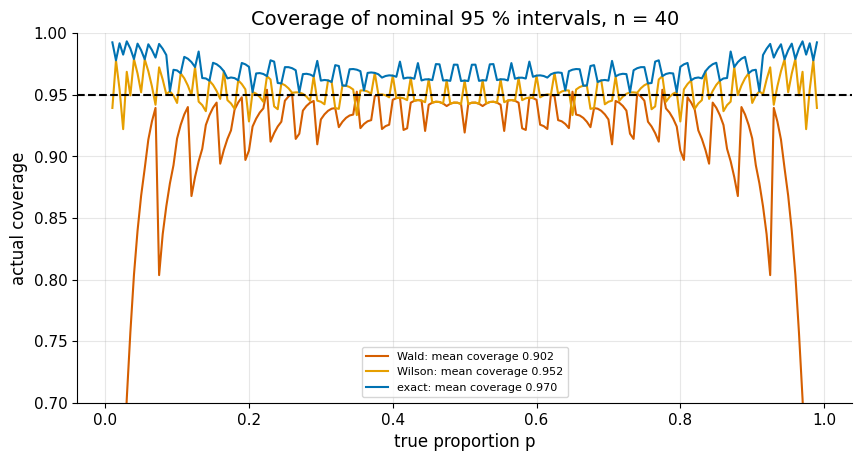

In [5]:
def intervals(k, n, conf=0.95):
    z = stats.norm.ppf(0.5 + conf / 2); p = k / n
    wald = np.stack([p - z * np.sqrt(p * (1 - p) / n), p + z * np.sqrt(p * (1 - p) / n)])
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n); half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    wilson = np.stack([centre - half, centre + half])
    lo = np.where(k == 0, 0.0, stats.beta.ppf((1 - conf) / 2, np.maximum(k, 1e-12), n - k + 1)); hi = np.where(k == n, 1.0, stats.beta.ppf(1 - (1 - conf) / 2, k + 1, np.maximum(n - k, 1e-12)))
    return {"Wald": wald, "Wilson": wilson, "exact": np.stack([lo, hi])}
def coverage(p_true, n, method):
    k = np.arange(n + 1); iv = intervals(k, n)[method]
    return stats.binom.pmf(k, n, p_true)[(iv[0] <= p_true) & (p_true <= iv[1])].sum()
p_grid = np.linspace(0.01, 0.99, 197); n_f = 40
cov_curves = {m: np.array([coverage(p, n_f, m) for p in p_grid]) for m in ("Wald", "Wilson", "exact")}
fig, ax = plt.subplots(figsize=(10, 4.8))
for m, c in zip(cov_curves, [HIGHLIGHT, SIM, MAIN]): ax.plot(p_grid, cov_curves[m], color=c, label=f"{m}: mean coverage {cov_curves[m].mean():.3f}")
ax.axhline(0.95, color="black", linestyle="--"); ax.set_ylim(0.7, 1.0); ax.set_xlabel("true proportion p"); ax.set_ylabel("actual coverage"); ax.set_title("Coverage of nominal 95 % intervals, n = 40"); ax.legend(fontsize=8)
plt.show()
assert cov_curves["Wald"].min() < 0.85 and cov_curves["exact"].min() >= 0.95 - 1e-9 and cov_curves["Wilson"].mean() > cov_curves["Wald"].mean()

## 8. 3D visuals

### 8.1 Static: coverage of the Wald interval over $(n,p)$
The exact coverage surface of the Wald interval: it **dips** badly for small $n$ and for $p$ near 0 or 1 (a "canyon" near the edges), and rises towards 95 % only for large $n$ and moderate $p$. The surface is a picture of why the rule of thumb "$np\ge10$" exists.

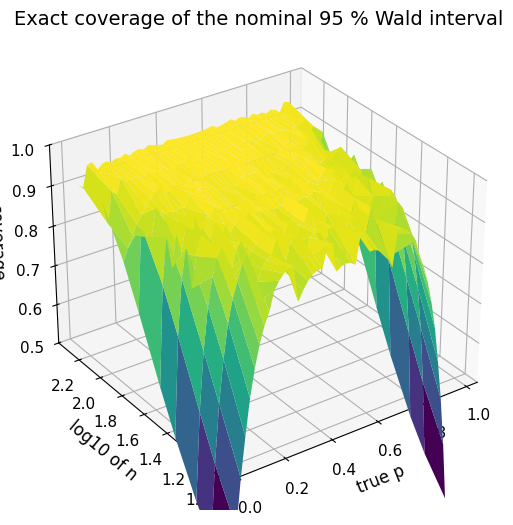

worst coverage on the grid: 0.183 (n = 10) | at n = 200 and p = 0.5: 0.944


In [6]:
n_axis = np.array([10, 15, 20, 30, 40, 60, 80, 120, 200]); p_axis = np.linspace(0.02, 0.98, 49)
CovW = np.array([[coverage(p, n, "Wald") for p in p_axis] for n in n_axis])
Pg, Ng = np.meshgrid(p_axis, np.log10(n_axis))
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Pg, Ng, CovW, cmap="viridis", edgecolor="none")
ax.set_xlabel("true p"); ax.set_ylabel("log10 of n"); ax.set_zlabel("coverage"); ax.set_zlim(0.5, 1.0); ax.set_title("Exact coverage of the nominal 95 % Wald interval"); ax.view_init(elev=30, azim=-125)
plt.show()
print(f"worst coverage on the grid: {CovW.min():.3f} (n = {n_axis[np.unravel_index(CovW.argmin(), CovW.shape)[0]]}) | at n = 200 and p = 0.5: {CovW[-1, 24]:.3f}")
assert CovW.min() < 0.75 and CovW[-1, 24] > 0.93

### 8.2 Interactive Plotly version of 8.1
Hover to read the exact coverage.

In [7]:
fig = go.Figure(go.Surface(x=p_axis, y=n_axis, z=CovW, colorscale="Viridis"))
fig.update_layout(title="Coverage of the Wald interval", width=760, height=560, scene=dict(xaxis_title="true p", yaxis_title="n", zaxis_title="coverage", zaxis=dict(range=[0.5, 1.0]), yaxis_type="log"))
fig.show()

### 8.3 Static: margin of error over $(n,\sigma)$
The margin $z\sigma/\sqrt n$ is a smooth surface: steep for small $n$, flat for large; it shows at a glance how many observations buy how much precision.

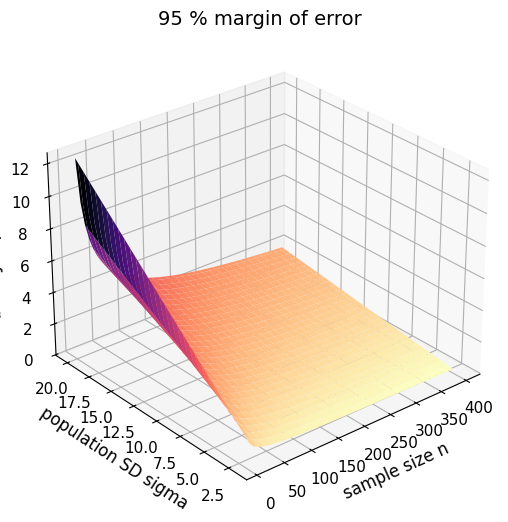

In [8]:
n_g = np.linspace(10, 400, 60); s_g = np.linspace(2, 20, 60)
Ng2, Sg = np.meshgrid(n_g, s_g)
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Ng2, Sg, 1.96 * Sg / np.sqrt(Ng2), cmap="magma_r", edgecolor="none")
ax.set_xlabel("sample size n"); ax.set_ylabel("population SD sigma"); ax.set_zlabel("margin of error"); ax.set_title("95 % margin of error"); ax.view_init(elev=28, azim=-130)
plt.show()

## 9. Simulation vs theory

### 9.1 Coverage of the $t$ interval under different populations
Simulate 40,000 samples of size 25 from a Normal, a right-skewed (Exponential) and a heavy-tailed (Student $t_3$) population and record how often the $t$-interval covers the true mean. It is exact for the Normal, slightly low for the skewed population and fine for the heavy tail at this sample size.

In [9]:
def cover_t(draw, true_mean, n, reps=40_000):
    x = draw((reps, n)); m, se = x.mean(axis=1), x.std(axis=1, ddof=1) / np.sqrt(n); tc = stats.t(n - 1).ppf(0.975)
    return np.mean((m - tc * se <= true_mean) & (true_mean <= m + tc * se))
rows = []
for name, draw, tm in [("Normal", lambda s: rng.normal(30, 8, s), 30), ("Exponential (skewed)", lambda s: rng.exponential(30, s), 30), ("Student t3 (heavy tails)", lambda s: 30 + 8 * rng.standard_t(3, s), 30)]:
    rows.append({"population": name, "n = 10": cover_t(draw, tm, 10), "n = 25": cover_t(draw, tm, 25), "n = 100": cover_t(draw, tm, 100)})
cov_t = pd.DataFrame(rows); print(cov_t.round(4).to_string(index=False))
assert abs(cov_t.iloc[0, 2] - 0.95) < 0.006 and cov_t.iloc[1, 2] < 0.95 and cov_t.iloc[1, 3] > cov_t.iloc[1, 1]

              population  n = 10  n = 25  n = 100
                  Normal  0.9500  0.9509   0.9491
    Exponential (skewed)  0.9025  0.9234   0.9410
Student t3 (heavy tails)  0.9576  0.9559   0.9548


### 9.2 The variance interval and non-Normal data
The chi-square interval for $\sigma$ is *not* robust: with Exponential data its coverage collapses even at $n=100$.

In [10]:
def cover_sigma(draw, true_sd, n, reps=30_000):
    x = draw((reps, n)); s2 = x.var(axis=1, ddof=1)
    lo = np.sqrt((n - 1) * s2 / stats.chi2(n - 1).ppf(0.975)); hi = np.sqrt((n - 1) * s2 / stats.chi2(n - 1).ppf(0.025))
    return np.mean((lo <= true_sd) & (true_sd <= hi))
print(f"Normal data: coverage {cover_sigma(lambda s: rng.normal(0, 8, s), 8, 25):.4f} | Exponential data (SD = mean = 30): coverage at n = 25: {cover_sigma(lambda s: rng.exponential(30, s), 30, 25):.4f}, at n = 100: {cover_sigma(lambda s: rng.exponential(30, s), 30, 100):.4f}")
assert abs(cover_sigma(lambda s: rng.normal(0, 8, s), 8, 25) - 0.95) < 0.007 and cover_sigma(lambda s: rng.exponential(30, s), 30, 100) < 0.9

Normal data: coverage 0.9495 | Exponential data (SD = mean = 30): coverage at n = 25: 0.7180, at n = 100: 0.6862


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
x = rng.normal(31.2, 8.4, 25)
print("t interval: stats.t.interval(0.95, df=len(x)-1, loc=x.mean(), scale=stats.sem(x)) ->", np.round(stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x)), 3))
print("normal interval: stats.norm.interval(0.95, loc, scale) ->", np.round(stats.norm.interval(0.95, loc=x.mean(), scale=x.std(ddof=1) / np.sqrt(len(x))), 3))
print("variance interval: (n-1) s^2 / chi2.ppf([0.975, 0.025], n-1) ->", np.round((len(x) - 1) * x.var(ddof=1) / stats.chi2.ppf([0.975, 0.025], len(x) - 1), 2))
res = stats.binomtest(3, 40); print("exact interval for 3 of 40: stats.binomtest(3, 40).proportion_ci(method='exact') ->", np.round(res.proportion_ci(confidence_level=0.95, method="exact"), 4), "| Wilson:", np.round(res.proportion_ci(method="wilson"), 4))
bs = stats.bootstrap((x,), np.mean, n_resamples=4000, confidence_level=0.95, method="BCa", random_state=1); print("bootstrap BCa interval for the mean:", np.round([bs.confidence_interval.low, bs.confidence_interval.high], 3))
print("sample size for a margin m: n = (z sigma / m)^2 ->", math.ceil((stats.norm.ppf(0.975) * 8.4 / 2) ** 2))
print("standard error: stats.sem(x) =", round(stats.sem(x), 4))

t interval: stats.t.interval(0.95, df=len(x)-1, loc=x.mean(), scale=stats.sem(x)) -> [31.77  38.578]
normal interval: stats.norm.interval(0.95, loc, scale) -> [31.941 38.406]
variance interval: (n-1) s^2 / chi2.ppf([0.975, 0.025], n-1) -> [ 41.46 131.61]
exact interval for 3 of 40: stats.binomtest(3, 40).proportion_ci(method='exact') -> [0.0157 0.2039] | Wilson: [0.0258 0.1986]
bootstrap BCa interval for the mean: [31.939 38.395]
sample size for a margin m: n = (z sigma / m)^2 -> 68
standard error: stats.sem(x) = 1.6493


## 11. Real-world worked examples

---
### Example 1 (main): how long does a delivery take?

**Scenario.** A courier company timed **$n=25$** randomly chosen deliveries (minutes): sample mean $\bar x=31.2$ and sample standard deviation $s=8.4$. Delivery times are roughly bell-shaped.

**Questions**
1. Give a **95 % confidence interval for the mean** delivery time ($t$-interval). Compare it with the $z$-interval.
2. Give a 95 % confidence interval for the **standard deviation**.
3. How many deliveries must be timed to bring the **margin of error down to $\pm2$ minutes**?
4. By simulation, check the **coverage** of the interval for Normal and for skewed delivery times.

### 11.1 By hand
**Q1.** $\mathrm{SE}=s/\sqrt n=8.4/5=1.68$; $t_{24,0.975}=2.064$. Interval: $31.2\pm2.064\times1.68=31.2\pm3.47=\mathbf{(27.73,\ 34.67)}$. The $z$-interval would use 1.96: $31.2\pm3.29=(27.91,34.49)$, slightly too narrow for $n=25$.

**Q2.** $\chi^2_{24,0.025}=12.40$ and $\chi^2_{24,0.975}=39.36$: $\sigma\in\big(8.4\sqrt{24/39.36},\ 8.4\sqrt{24/12.40}\big)=(8.4\times0.781,\ 8.4\times1.391)=\mathbf{(6.56,\ 11.69)}$ minutes.

**Q3.** $n\ge(z\,s/m)^2=(1.96\times8.4/2)^2=67.8\Rightarrow\mathbf{68}$ deliveries (about 70 with the $t$ correction).

**Q4.** By simulation (below).

In [12]:
n_c, xbar_c, s_c = 25, 31.2, 8.4
se_c = s_c / np.sqrt(n_c)
t_int = stats.t.interval(0.95, n_c - 1, loc=xbar_c, scale=se_c); z_int = stats.norm.interval(0.95, loc=xbar_c, scale=se_c)
sd_int = np.sqrt((n_c - 1) * s_c**2 / stats.chi2.ppf([0.975, 0.025], n_c - 1))
n_need = math.ceil((1.96 * s_c / 2) ** 2)
print(f"Q1: t interval ({t_int[0]:.2f}, {t_int[1]:.2f}), half-width {t_int[1] - xbar_c:.2f} | z interval ({z_int[0]:.2f}, {z_int[1]:.2f})")
print(f"Q2: SD interval ({sd_int[0]:.2f}, {sd_int[1]:.2f})")
print(f"Q3: n for a margin of +/- 2 minutes: {n_need}; using the t critical value for that n: {math.ceil((stats.t.ppf(0.975, n_need - 1) * s_c / 2) ** 2)}")

Q1: t interval (27.73, 34.67), half-width 3.47 | z interval (27.91, 34.49)
Q2: SD interval (6.56, 11.69)
Q3: n for a margin of +/- 2 minutes: 68; using the t critical value for that n: 71


### 11.2 In code with `scipy`, and the asserts

In [13]:
assert np.allclose(t_int, (27.73, 34.67), atol=0.01) and np.allclose(z_int, (27.91, 34.49), atol=0.01) and np.allclose(sd_int, (6.56, 11.69), atol=0.01) and n_need == 68
assert np.isclose(stats.t.ppf(0.975, 24), 2.0639, atol=1e-3) and np.isclose(stats.chi2.ppf(0.025, 24), 12.401, atol=1e-2) and np.isclose(stats.chi2.ppf(0.975, 24), 39.364, atol=1e-2)
assert t_int[1] - t_int[0] > z_int[1] - z_int[0]                   # the t interval is wider
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Simulate 100,000 studies of 25 deliveries and count how often each kind of interval contains the true mean 31.2 and the true SD 8.4: for Normal times and for right-skewed Gamma times with the same mean and SD.

In [14]:
sim_g = np.random.default_rng(31); reps = 100_000
def run(draw):
    x = draw((reps, 25)); m, s = x.mean(axis=1), x.std(axis=1, ddof=1); se = s / 5
    return (np.mean((m - 2.0639 * se <= 31.2) & (31.2 <= m + 2.0639 * se)), np.mean((m - 1.96 * se <= 31.2) & (31.2 <= m + 1.96 * se)),
            np.mean((np.sqrt(24 * s**2 / 39.364) <= 8.4) & (8.4 <= np.sqrt(24 * s**2 / 12.401))))
shape_g = (31.2 / 8.4) ** 2; scale_g = 8.4**2 / 31.2
res_n, res_g = run(lambda sh: sim_g.normal(31.2, 8.4, sh)), run(lambda sh: sim_g.gamma(shape_g, scale_g, sh))
print(pd.DataFrame([res_n, res_g], index=["Normal times", "skewed (Gamma) times"], columns=["t interval for the mean", "z interval for the mean", "chi-square interval for the SD"]).round(4).to_string())
assert abs(res_n[0] - 0.95) < 0.004 and res_n[1] < res_n[0] and abs(res_n[2] - 0.95) < 0.005 and res_g[2] < res_n[2] and abs(res_g[0] - 0.95) < 0.015

                      t interval for the mean  z interval for the mean  chi-square interval for the SD
Normal times                            0.950                   0.9384                          0.9499
skewed (Gamma) times                    0.948                   0.9365                          0.9278


### 11.4 Plots with the regions shaded

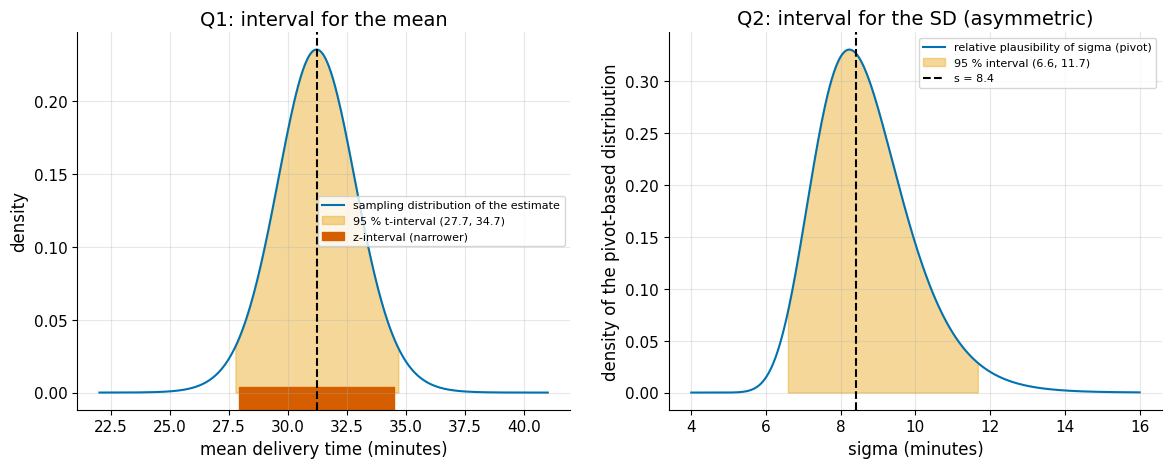

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
xs = np.linspace(22, 41, 400); pdf_t = stats.t(24, loc=xbar_c, scale=se_c).pdf(xs)
axes[0].plot(xs, pdf_t, color=MAIN, label="sampling distribution of the estimate"); axes[0].fill_between(xs, 0, pdf_t, where=(xs >= t_int[0]) & (xs <= t_int[1]), color=SIM, alpha=0.4, label=f"95 % t-interval ({t_int[0]:.1f}, {t_int[1]:.1f})")
axes[0].axvspan(z_int[0], z_int[1], ymin=0, ymax=0.06, color=HIGHLIGHT, label="z-interval (narrower)"); axes[0].axvline(xbar_c, color="black", linestyle="--"); axes[0].set_xlabel("mean delivery time (minutes)"); axes[0].set_ylabel("density"); axes[0].set_title("Q1: interval for the mean"); axes[0].legend(fontsize=8)
sgs = np.linspace(4, 16, 400); axes[1].plot(sgs, stats.chi2(24).pdf(24 * s_c**2 / sgs**2) * 2 * 24 * s_c**2 / sgs**3, color=MAIN, label="relative plausibility of sigma (pivot)")
axes[1].fill_between(sgs, 0, stats.chi2(24).pdf(24 * s_c**2 / sgs**2) * 2 * 24 * s_c**2 / sgs**3, where=(sgs >= sd_int[0]) & (sgs <= sd_int[1]), color=SIM, alpha=0.4, label=f"95 % interval ({sd_int[0]:.1f}, {sd_int[1]:.1f})"); axes[1].axvline(s_c, color="black", linestyle="--", label="s = 8.4")
axes[1].set_xlabel("sigma (minutes)"); axes[1].set_ylabel("density of the pivot-based distribution"); axes[1].set_title("Q2: interval for the SD (asymmetric)"); axes[1].legend(fontsize=8)
plt.show()

### 11.5 Interpretation and decision (Example 1)
- The mean delivery time is **between 27.7 and 34.7 minutes** (95 % confidence); the $z$-interval (27.9 to 34.5) is too narrow for $n=25$ and covers the true mean only **93.8 %** of the time in simulation, while the $t$-interval covers **95.0 %**.
- The spread is much less certain than the mean: the standard deviation lies between **6.6 and 11.7 minutes**, a range of almost a factor of two. The interval for $\sigma$ is less robust: for the skewed Gamma times its coverage is only **92.8 %** (the $t$ interval for the mean still reaches 94.8 %).
- To get the margin of error from $\pm3.5$ down to $\pm2$ minutes the company must time about **68 deliveries** (71 with the $t$ critical value), 2.7 times as many.
- **Decision.** Quote "31 minutes, give or take 3.5" to customers, plan staffing from the whole interval (28 to 35 minutes), and time more deliveries only if a margin of $\pm2$ minutes changes a decision. Do not describe a single delivery with this interval: a single delivery can be expected within about $\pm18$ minutes of the mean (a prediction interval).

---
### Example 2: a rare failure rate (when the Wald interval breaks)

**Scenario.** In a sample of **40 devices, 3 failed** within a year. What is a 95 % confidence interval for the failure probability?

**Questions**
1. Compute the Wald, Wilson and exact intervals.
2. Which interval would you report? Why is the Wald interval a problem here?
3. Over many repetitions, what is the true coverage of each method at $p=0.05$ and $n=40$?

### 11.6 By hand
**Q1.** $\hat p=3/40=0.075$. Wald: $0.075\pm1.96\sqrt{0.075\times0.925/40}=0.075\pm0.0816=\mathbf{(-0.0066,\ 0.1566)}$: **a negative lower limit**. Wilson: centre $\frac{0.075+1.96^2/80}{1+1.96^2/40}=\frac{0.1230}{1.0960}=0.1122$, half-width $\frac{1.96\sqrt{0.0017+0.0006}}{1.096}=0.0858\ \Rightarrow\ \mathbf{(0.026,\ 0.198)}$. The exact interval is computed below.

**Q2.** The Wald interval is wrong for a rare event; Wilson or the exact interval should be reported.

**Q3.** Coverage at $p=0.05$ from the exact Binomial sum (computed below).

Wald   : (-0.0066, 0.1566)  width 0.1632
Wilson : (0.0258, 0.1986)  width 0.1728
exact  : (0.0157, 0.2039)  width 0.1881
true coverage at p = 0.05, n = 40: {'Wald': np.float64(0.8681), 'Wilson': np.float64(0.952), 'exact': np.float64(0.9861)}


simulated coverage: {'Wald': 0.8679, 'Wilson': 0.9516, 'exact': 0.9861}


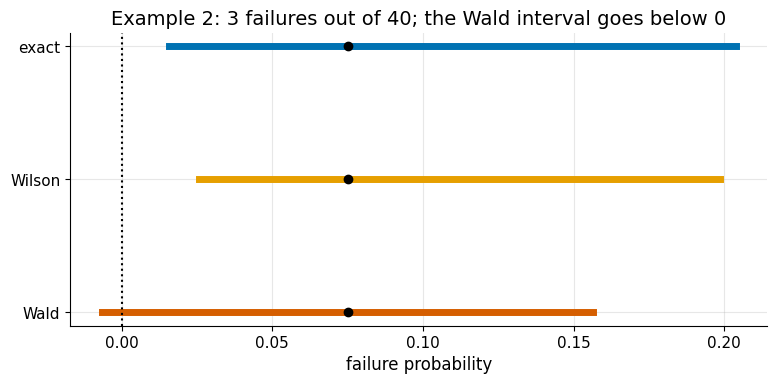

In [16]:
k_e, n_e = 3, 40
iv = {m: intervals(np.array([k_e]), n_e)[m][:, 0] for m in ("Wald", "Wilson", "exact")}
for m, v in iv.items(): print(f"{m:7s}: ({v[0]:.4f}, {v[1]:.4f})  width {v[1] - v[0]:.4f}")
cov_005 = {m: coverage(0.05, n_e, m) for m in ("Wald", "Wilson", "exact")}
print("true coverage at p = 0.05, n = 40:", {m: round(c, 4) for m, c in cov_005.items()})
assert iv["Wald"][0] < 0 and np.allclose(iv["Wilson"], (0.026, 0.198), atol=0.002) and cov_005["Wald"] < 0.92 and cov_005["exact"] >= 0.95
sim_e = np.random.default_rng(5).binomial(n_e, 0.05, 400_000); ivs = intervals(sim_e, n_e)
sim_cov = {m: np.mean((v[0] <= 0.05) & (0.05 <= v[1])) for m, v in ivs.items()}
print("simulated coverage:", {m: round(float(c), 4) for m, c in sim_cov.items()}); assert abs(sim_cov["Wald"] - cov_005["Wald"]) < 0.004
fig, ax = plt.subplots(figsize=(9, 3.8))
for y, (m, c) in enumerate(zip(("Wald", "Wilson", "exact"), (HIGHLIGHT, SIM, MAIN))): ax.plot(iv[m], [y, y], color=c, linewidth=5, label=m); ax.plot([0.075], [y], "ko")
ax.axvline(0, color="black", linestyle=":"); ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["Wald", "Wilson", "exact"]); ax.set_xlabel("failure probability"); ax.set_title("Example 2: 3 failures out of 40; the Wald interval goes below 0")
plt.show()

### 11.7 Interpretation and decision (Example 2)
- With 3 failures out of 40 the three methods disagree: **Wald (-0.007, 0.157)** goes below zero, **Wilson (0.026, 0.199)** and the **exact interval (0.016, 0.204)** do not. The exact interval is the widest, because it guarantees at least 95 % coverage.
- At the true rate $p=0.05$ the **Wald interval covers only 86.8 %** of the time (simulation 86.8 %), Wilson 95.2 % and the exact interval 98.6 %: the "95 % Wald interval" is really an 87 % interval here.
- **Decision.** Report the **Wilson** interval (a good balance of accuracy and width) or the exact one when a guarantee is required: "between 2.6 % and 19.9 % of the devices fail within a year". An upper limit near 20 % shows that 40 devices cannot demonstrate a failure rate below, say, 5 %; test more devices.

---
### Example 3: machine precision and the sample size for a standard deviation

**Scenario.** A filling machine should have a standard deviation of at most **0.8 g**. A sample of **12** fills gives $s=0.8$ g.

**Questions**
1. What is the 95 % confidence interval for $\sigma$, and is the claim $\sigma\le0.8$ supported?
2. How many fills are needed to know $\sigma$ to within about **$\pm20\,\%$** (relative half-width)?
3. How does the interval's width change with the sample size?

### 11.8 By hand
**Q1.** $\chi^2_{11,0.025}=3.816$, $\chi^2_{11,0.975}=21.92$: $\sigma\in\big(0.8\sqrt{11/21.92},\,0.8\sqrt{11/3.816}\big)=(0.8\times0.708,\,0.8\times1.698)=\mathbf{(0.57,\ 1.36)}$ g. The upper limit exceeds 0.8, so the data **cannot** show that the machine meets the specification.

**Q2.** For large $n$ the relative standard error of $s$ is about $1/\sqrt{2(n-1)}$, so a 95 % half-width of 20 % needs $1.96/\sqrt{2(n-1)}\le0.2$, i.e. $n\ge1+\frac{1.96^2}{2(0.04)}=\mathbf{50}$.

Q1: 95 % interval for sigma (0.567, 1.358) g | Q2: n = 50 for about +/-20 % | relative half-width of the interval by n: {5: np.float64(1.137), 12: np.float64(0.495), 25: np.float64(0.305), 49: np.float64(0.208), 100: np.float64(0.142), 400: np.float64(0.07)}
simulation: coverage of the interval for sigma = 0.8: 0.9502 | share of samples whose upper limit is below 0.8 (spec proven): 0.0247


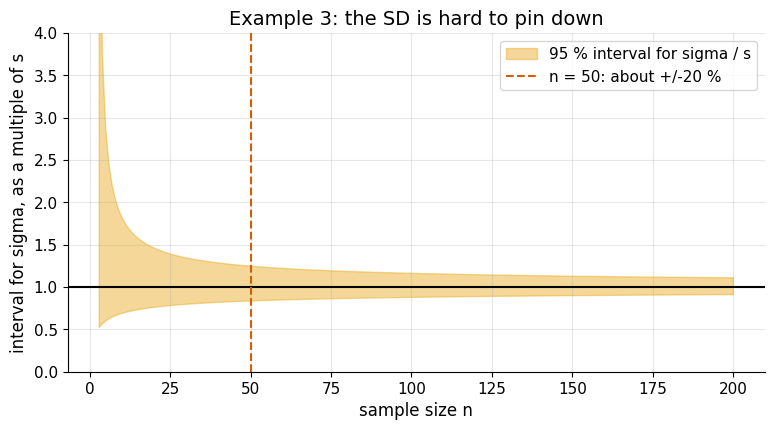

In [17]:
n_m, s_m = 12, 0.8
sig_int = s_m * np.sqrt((n_m - 1) / stats.chi2.ppf([0.975, 0.025], n_m - 1))
n_rel = math.ceil(1 + 1.96**2 / (2 * 0.2**2))
rel_w = {n_: (np.sqrt((n_ - 1) / stats.chi2.ppf(0.025, n_ - 1)) - np.sqrt((n_ - 1) / stats.chi2.ppf(0.975, n_ - 1))) / 2 for n_ in (5, 12, 25, 49, 100, 400)}
print(f"Q1: 95 % interval for sigma ({sig_int[0]:.3f}, {sig_int[1]:.3f}) g | Q2: n = {n_rel} for about +/-20 % | relative half-width of the interval by n: {({k: round(v, 3) for k, v in rel_w.items()})}")
assert np.allclose(sig_int, (0.567, 1.358), atol=0.003) and n_rel == 50 and abs(rel_w[49] - 0.2) < 0.03
g_m = np.random.default_rng(7); sm = g_m.normal(0, 0.8, (200_000, 12)).std(axis=1, ddof=1); lo_m = sm * np.sqrt(11 / 21.92); hi_m = sm * np.sqrt(11 / 3.816)
print(f"simulation: coverage of the interval for sigma = 0.8: {np.mean((lo_m <= 0.8) & (0.8 <= hi_m)):.4f} | share of samples whose upper limit is below 0.8 (spec proven): {np.mean(hi_m < 0.8):.4f}")
assert abs(np.mean((lo_m <= 0.8) & (0.8 <= hi_m)) - 0.95) < 0.004
fig, ax = plt.subplots(figsize=(9, 4.4)); nn_m = np.arange(3, 201); lowr = np.sqrt((nn_m - 1) / stats.chi2.ppf(0.975, nn_m - 1)); highr = np.sqrt((nn_m - 1) / stats.chi2.ppf(0.025, nn_m - 1))
ax.fill_between(nn_m, lowr, highr, color=SIM, alpha=0.4, label="95 % interval for sigma / s"); ax.axhline(1, color="black"); ax.axvline(50, color=HIGHLIGHT, linestyle="--", label="n = 50: about +/-20 %"); ax.set_ylim(0, 4); ax.set_xlabel("sample size n"); ax.set_ylabel("interval for sigma, as a multiple of s"); ax.set_title("Example 3: the SD is hard to pin down"); ax.legend()
plt.show()

### 11.9 Interpretation and decision (Example 3)
- From 12 fills with $s=0.8$ g the standard deviation lies between **0.57 and 1.36 g**. Since 1.36 is well above the specification of 0.8 g, the data **cannot show that the machine meets the specification**; they cannot show that it fails either, because 0.8 is inside the interval.
- To know $\sigma$ to within about $\pm20\,\%$ one needs about **50 fills** (the relative half-width is 20.8 % at $n=49$ and 14 % at $n=100$); a standard deviation is much harder to estimate than a mean (the relative error of $s$ is about $1/\sqrt{2(n-1)}$).
- Simulation confirms the 95 % coverage (0.950) and shows that **even if the true SD is exactly 0.8 g, only 2.5 % of 12-fill samples would prove the machine within specification** (upper limit below 0.8).
- **Decision.** Take at least 50 fills for a capability study, and use a one-sided upper limit for $\sigma$ when the only question is "is it below 0.8?".

## 12. Where it is used

### Statistics
- **Reporting every estimate** (means, proportions, regression coefficients, odds ratios) together with an interval; the link between intervals and tests (06_03); **non-inferiority and equivalence** claims are made from interval limits.
- **Sample-size planning** for studies and surveys: choose $n$ from the target margin of error.

### Data science
- **Dashboards and A/B tests:** conversion rates, revenue per user and latency percentiles with intervals; Wilson or exact intervals for small counts; bootstrap intervals for medians (05_04).
- **Forecast and KPI uncertainty** (the "cone" around a forecast is a family of intervals).

### ML and AI
- **Model evaluation:** an accuracy of 91 % on 500 test examples is $91\%\pm2.5$ points (a Wilson interval); two models whose intervals overlap heavily are not clearly different (05_05 gave the guaranteed sizes).
- **Uncertainty estimates:** bootstrap or ensemble intervals for predictions, **conformal prediction** intervals with guaranteed coverage, calibration of predicted intervals (does the 90 % interval contain 90 % of the truths?).

## 13. Common pitfalls and misconceptions

- **"There is a 95 % probability that the true mean lies in this interval"** is the *Bayesian* reading; the frequentist statement is about the procedure: 95 % of such intervals cover the truth. For one computed interval the truth is either inside or not.
- **Overlap of two intervals does not mean "no difference":** compare the difference with its own interval (06_04).
- **Using $z$ instead of $t$ for small samples** makes the interval too narrow; with $n<30$ use $t$.
- **Wald for rare events** can give negative or too-narrow intervals; use Wilson or exact methods.
- **Variance intervals are fragile:** the chi-square interval assumes Normal data; with skewed data its coverage is far below nominal (9.2). Use the bootstrap.
- **A wider interval is not worse:** it may be honest; narrowing it requires more data, not a smaller confidence level.
- **The interval does not cover the spread of individual values:** a CI for the mean delivery time is not a range for a single delivery (that is a *prediction* interval, much wider).
- **Multiple intervals:** if you compute 20 intervals at 95 %, one is expected to miss (06_06).

## 14. Exercises

1. A survey asks 1,000 people and 520 say yes. Give the Wilson 95 % interval for the proportion and the margin of error. How many people are needed for a margin of $\pm2$ points?
2. Compute the 95 % $t$-critical value for $n=5,10,30,100$ and compare each with 1.96. For which $n$ does the $z$ interval become acceptable?
3. A sample of 16 measurements has mean 100 and SD 12. Give 90 %, 95 % and 99 % intervals for the mean and describe how the width changes.
4. A 95 % confidence interval for a mean is (10, 14). Which statements are correct? (a) the sample mean is 12; (b) 95 % of the data lie in (10, 14); (c) the test of $H_0:\mu=15$ at the 5 % level would reject; (d) there is a 95 % probability that $\mu\in(10,14)$.
5. Simulate 1,000 intervals of size $n=20$ from a Normal population and count the proportion that cover the true mean; repeat with $\alpha=0.20$ and explain.
6. (Harder) For Exponential data with mean 100 and $n=30$, compare by simulation the coverage of the $t$ interval and of the bootstrap percentile interval (500 resamples, 2,000 data sets).

Solutions are at the end.

## 15. Summary table

| Parameter | Interval | Notes |
|---|---|---|
| Mean, $\sigma$ known | $\bar x\pm z\sigma/\sqrt n$ | exact for Normal data |
| Mean | $\bar x\pm t_{n-1}s/\sqrt n$ | robust for moderate $n$ |
| Variance | $\big(\frac{(n-1)s^2}{\chi^2_{hi}},\frac{(n-1)s^2}{\chi^2_{lo}}\big)$ | needs Normal data |
| Proportion | Wilson (or exact) | avoid Wald for small $n$ or rare events |
| Sample size | $n=(z\sigma/m)^2$; $n=z^2/(4m^2)$ for $p$ | halving $m$ needs $4n$ |
| Any statistic | bootstrap (05_04) | no formula needed |
| `scipy` | `stats.t.interval`, `stats.binomtest(...).proportion_ci` | `stats.bootstrap` |

## Solutions

In [18]:
k1, n1 = 520, 1000; iw = intervals(np.array([k1]), n1)["Wilson"][:, 0]
print(f"1: Wilson interval ({iw[0]:.4f}, {iw[1]:.4f}), margin about {(iw[1] - iw[0]) / 2 * 100:.2f} points | n for +/-2 points: {math.ceil(1.96**2 / (4 * 0.02**2))}")
print("2: t critical values", {n_: round(stats.t.ppf(0.975, n_ - 1), 3) for n_ in (5, 10, 30, 100)}, "| z = 1.96 becomes acceptable around n = 30 to 100 (error below 5 %)")
for conf in (0.90, 0.95, 0.99):
    h = stats.t.ppf(0.5 + conf / 2, 15) * 12 / 4; print(f"3: {conf:.0%}: 100 +/- {h:.2f} -> ({100 - h:.2f}, {100 + h:.2f}), width {2 * h:.2f}")
print("4: (a) correct (the centre of a symmetric interval); (b) wrong (an interval for the mean, not for the data); (c) correct (15 lies outside (10, 14)); (d) not correct in the frequentist reading")
g5 = np.random.default_rng(5)
for alpha in (0.05, 0.20):
    c = 0
    for _ in range(1000):
        x_ = g5.normal(30, 8, 20); h = stats.t.ppf(1 - alpha / 2, 19) * x_.std(ddof=1) / np.sqrt(20); c += abs(x_.mean() - 30) <= h
    print(f"5: alpha = {alpha}: {c / 1000:.3f} of 1,000 intervals cover the mean (nominal {1 - alpha:.2f})")
cv_t = cv_b = 0; reps6 = 1000
for _ in range(reps6):
    d6 = g5.exponential(100, 30); h = stats.t.ppf(0.975, 29) * d6.std(ddof=1) / np.sqrt(30); cv_t += abs(d6.mean() - 100) <= h
    bm = g5.choice(d6, (400, 30)).mean(axis=1); lo6, hi6 = np.percentile(bm, [2.5, 97.5]); cv_b += lo6 <= 100 <= hi6
print(f"6: coverage for Exponential data, n = 30: t interval {cv_t / reps6:.3f}, bootstrap percentile {cv_b / reps6:.3f}")
assert iw[0] < 0.52 < iw[1]

1: Wilson interval (0.4890, 0.5508), margin about 3.09 points | n for +/-2 points: 2401
2: t critical values {5: np.float64(2.776), 10: np.float64(2.262), 30: np.float64(2.045), 100: np.float64(1.984)} | z = 1.96 becomes acceptable around n = 30 to 100 (error below 5 %)
3: 90%: 100 +/- 5.26 -> (94.74, 105.26), width 10.52
3: 95%: 100 +/- 6.39 -> (93.61, 106.39), width 12.79
3: 99%: 100 +/- 8.84 -> (91.16, 108.84), width 17.68
4: (a) correct (the centre of a symmetric interval); (b) wrong (an interval for the mean, not for the data); (c) correct (15 lies outside (10, 14)); (d) not correct in the frequentist reading


5: alpha = 0.05: 0.945 of 1,000 intervals cover the mean (nominal 0.95)
5: alpha = 0.2: 0.803 of 1,000 intervals cover the mean (nominal 0.80)


6: coverage for Exponential data, n = 30: t interval 0.927, bootstrap percentile 0.904


**1.** The Wilson interval is **(0.489, 0.551)**, a margin of about **3.1 points**. For $\pm2$ points: $n=1.96^2/(4\times0.02^2)=\mathbf{2{,}401}$ people (the worst case $p=\tfrac12$).

**2.** $t_{0.975}$: 2.776 ($n=5$), 2.262 ($n=10$), 2.045 ($n=30$), 1.984 ($n=100$). The $z$ value 1.96 is within about 5 % from $n=30$ on and within 1 % at $n=100$.

**3.** 90 %: $100\pm5.26$; 95 %: $100\pm6.39$; 99 %: $100\pm8.84$. Widths 10.5, 12.8 and 17.7: higher confidence means a wider interval (99 % is 38 % wider than 95 %).

**4.** (a) correct, the centre of a symmetric interval is the sample mean 12. (b) **wrong**: the interval is for the *mean*, not for the individual data. (c) correct, 15 is outside the interval. (d) not correct in the frequentist reading (it is the Bayesian reading, Module 07).

**5.** With $\alpha=0.05$ about 94.5 % of 1,000 intervals cover the mean; with $\alpha=0.20$ about 80 %. The coverage equals $1-\alpha$ in the long run, with simulation noise of about $\pm0.7$ points for 1,000 repetitions.

**6.** For Exponential data with $n=30$ the $t$ interval covers **92.7 %** and the bootstrap percentile interval **90.4 %**: both fall below 95 % for a skewed population and a small sample, and the percentile bootstrap is the worse of the two (BCa or a transformation would help).